# HypeCheck: signal or noise?
### Do yesterday's archived X posts improve next-day memecoin forecasts?
**Veritas AI International High School Hackathon 2026 · AI + Finance**
**Team:** Nathaniel Wong · Aaden Yick · Alastair Chu — Malvern College Hong Kong

**Our user:** a beginner crypto investor who sees a bullish post and wonders whether to trust it.
**Our test:** compare an AI sentiment model with simple rules on later, unseen-by-training market dates.

> **Finding:** the market-history model got 54.40% right. Adding post counts and sentiment brought that to 53.61%. We observed posts in 219 of 2,509 test rows.

**How to run:** choose **Runtime → Run all**. No keys or uploads. Saved outputs are included for reading without running. We train the direction classifiers during the run; the default reuses verified, frozen sentiment scores.

**Try the [browser replay](https://adeviwon.github.io/hypecheck/)** to read a pair of archived DOGE posts, compare the forecasts and reveal the outcome.

*This project is a prototype and is not financial advice. We had examined the final dates before, so the result is exploratory.*

### Before you start: automatic setup
Run this once. Installation details are kept out of the main explanation. In Colab, click **Show code** on a setup cell if you want to inspect it.

In [1]:
#@title Prepare the Python environment
import sys, subprocess, json, hashlib, urllib.request
from pathlib import Path
if 'google.colab' in sys.modules:
    pins = ['numpy==2.5.4', 'pandas==3.1.1', 'pyarrow==26.0.1',
            'scikit-learn==1.9.1', 'requests==2.34.2',
            'transformers==5.23.0', 'safetensors==0.8.0']
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *pins], check=True)
print('Environment ready. Direction models will be trained in this run.')

Environment ready. Direction models will be trained in this run.


## 1. Load the data
We combine **original X posts** with **daily Binance prices for 13 memecoins**. No posts are selected to meet a bullish/bearish quota.

The short loader downloads exact, **commit-pinned and SHA-256-checked** files. It does not download precomputed forecasts. The full method remains inspectable in the [source code](https://github.com/adeviwon/hypecheck/blob/e396d50d1ac40eabd648f1cedc4d9316e80e7759/headline_study.py).

**What to look for:** a verification message, followed by a small sample of real posts in Section 2.

In [2]:
#@title Download and verify the study files
REVISION = '2ce94ac955100ec37968fdfa404e3ae7af8e430b'
VERIFIED_FILES = {'colab_setup.py': '48e912fec0f69329b2ed93ef5da6cca4890ec191fa6e84367eece7be2a246cb4', 'notebook_support.py': 'e5dd57e29724851b18e5bd2ebfb9b226b4bb5a72be36b4144a51503ab2e01e70'}
for name, expected in VERIFIED_FILES.items():
    url = f'https://raw.githubusercontent.com/adeviwon/hypecheck/{REVISION}/{name}'
    with urllib.request.urlopen(url, timeout=120) as response:
        payload = response.read()
    if hashlib.sha256(payload).hexdigest() != expected:
        raise ValueError('Setup verification failed: ' + name)
    Path(name).write_bytes(payload)
from colab_setup import prepare
RECOMPUTE_SENTIMENT = False  #@param {type: "boolean"}
prepare(recompute_sentiment=RECOMPUTE_SENTIMENT)
from notebook_support import table, accuracy_table, accuracy_chart, replay

Verified source and market data. Sentiment: verified cache


In [3]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
import pipeline as core
from expanded_inputs import select_posts, load, split_data, COINS
raw, _ = core.load_posts()
selected = select_posts(raw)
print(f'Loaded {len(raw):,} source rows; {len(selected):,} eligible original posts.')
print('Coins:', ', '.join(COINS))

Loaded 104,379 source rows; 1,773 eligible original posts.
Coins: DOGE, SHIB, PEPE, BONK, FLOKI, WIF, TRUMP, NEIRO, PENGU, PNUT, TURBO, BOME, MEME


## 2. Look at the data before training
We remove duplicates and keep supported coin tags. We assign posts to the later of publication and archive collection when both timestamps exist. Otherwise, we use publication time. The first archive timestamp was missing for 231 of 232 eligible posts assigned to test dates. All 1,464 training posts were tagged Discord by the archive. The test archive tagged 231 posts as web and one as both.

**Prediction task:** use posts available on one UTC day to predict whether the coin's **next-day close is above its open**. A flat day counts as “not up.”

**Read the sample below:** FinTwitBERT assigns tone to the wording. The direction model estimates whether the coin will rise.

In [4]:
sample = selected[['available_at', 'text']].head(3).copy()
sample['available_at'] = sample.available_at.dt.strftime('%Y-%m-%d %H:%M UTC')
sample.columns = ['Available from', 'Example post']
table(sample, 'Three real posts before any direction model is trained')
print('One observation in the evaluation = one coin on one UTC day, not one tweet.')

Available from,Example post
2024-03-22 04:49 UTC,Take partial profit fam 🔥 $bome #bome
2024-03-22 06:29 UTC,$doge legit best looking major by a mile atm imo
2024-03-22 07:19 UTC,The doge of this cycle should go for the next round anytime now IMO.\n\nAfter consolidation comes continuation.\nInvalidation below the horizontal.\n\n$FLOKI


One observation in the evaluation = one coin on one UTC day, not one tweet.


## 3. Split the data by time—not at random
| Partition | Purpose |
|---|---|
| Training: earliest dates | Learn the classifier and preprocessing |
| Validation: middle dates | Choose regularisation without using the test |
| Test: latest dates | Report the final accuracy |

We leave a **one-day gap** at each boundary. The rules assign posts and market features to earlier UTC dates. Training and test share **zero UTC dates**. The final dates were examined in earlier research.

**What the output means:** the test dates must come after training and validation. The assertions stop execution if the boundaries overlap.

In [5]:
raw, scored, prices, frame = load()
train, validation, test = split_data(frame)
table(pd.DataFrame([{
    'Partition': name, 'First day': str(part.date.min().date()),
    'Last day': str(part.date.max().date()), 'Coin-days': len(part),
    'UTC dates': part.date.nunique(),
} for name, part in [('Train', train), ('Validation', validation), ('Test', test)]]))
assert train.date.max() + pd.Timedelta(days=1) < validation.date.min()
assert validation.date.max() + pd.Timedelta(days=1) < test.date.min()
assert not set(train.date) & set(test.date)
print('PASS: chronological partitions, purge gaps and no shared train/test dates.')

/Users/aaden/.cache/uv/archive-v0/BRHPyLtndpsinxCm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Partition,First day,Last day,Coin-days,UTC dates
Train,2024-03-01,2025-09-29,6171,578
Validation,2025-10-01,2026-04-10,2496,192
Test,2026-04-12,2026-10-21,2509,193


PASS: chronological partitions, purge gaps and no shared train/test dates.


## 4. Baselines: can we beat simple guesses?
Before using AI, test rules that read **no text**:

1. **Always up:** predict that every coin rises.
2. **Previous-day direction:** copy yesterday's open-to-close direction.
3. **Training majority:** always predict the more common training direction.

**Accuracy** is the percentage of correct directions. **Brier error** measures probability error; lower is better. For that score, training prevalence is the fair constant-probability reference—not a hard 0/1 guess.

In [6]:
from headline_study import previous_day
persistence = np.full(len(test), np.nan)
for coin in COINS:
    mask = test.coin.eq(coin).to_numpy()
    persistence[mask] = test.loc[mask, 'date'].map(previous_day(prices[coin]))
assert np.isfinite(persistence).all()
y = test.actual_up.to_numpy()
baselines = {'Always up': np.ones(len(test)), 'Previous-day direction': persistence,
             'Training majority': np.full(len(test), float(train.actual_up.mean() >= .5)),
             'Training prevalence': np.full(len(test), train.actual_up.mean())}
table(pd.DataFrame([{'Rule': name, 'Accuracy': f"{core.scores(y, p)['accuracy']:.2%}",
                    'Brier error': f"{core.scores(y, p)['brier']:.4f}"}
                   for name, p in baselines.items()]))

Rule,Accuracy,Brier error
Always up,46.07%,0.5393
Previous-day direction,48.51%,0.5149
Training majority,53.93%,0.4607
Training prevalence,53.93%,0.2486


## 5. Model 1: turn sentiment into a direction forecast
**Post → frozen FinTwitBERT sentiment → daily features → trained logistic regression → up / not up.**

The classifier sees sentiment, post count, disagreement and coin identity. The pretrained encoder is **not fine-tuned**. We fit three regularisation settings on training data and choose using validation Brier error. The probability threshold is fixed at 0.5.

**Fair test:** compare posts and coin identity against coin identity alone. Then compare lagged price and volume with and without the post inputs. Both market models include coin identity, and the post inputs combine count, presence and sentiment.

In [7]:
done = subprocess.run([sys.executable, 'headline_study.py', '--universe', 'expanded'],
                      text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
Path('artifacts/training-log.txt').write_text(done.stdout)
if done.returncode:
    print(done.stdout)  # Show the diagnostic if training fails.
done.check_returncode()
report = json.loads(Path('docs/headline-report.json').read_text())
pred = pd.read_csv('artifacts/headline-predictions.csv')
accuracy_table(report, ['Sentiment + coin', 'Coin only', 'Market only', 'Market + sentiment'])
print('Fitted models, selected settings on validation, and saved every test prediction.')

Method,Correct directions,Brier error (lower is better)
Sentiment + coin,53.09%,0.2494
Coin only,53.93%,0.2485
Market only,54.40%,0.2477
Market + sentiment,53.61%,0.2486


Fitted models, selected settings on validation, and saved every test prediction.


## 6. Where Model 1 goes wrong
A useful submission shows failures, not just successes. Below are the **three most confident wrong calls with observed posts**. We show their real prior-day inputs and actual outcomes.

These examples are selected for explanation only. We do **not** tune the model after looking at them. A wrong forecast does not prove the author was fraudulent.

In [8]:
wrong = pred[(pred['Sentiment + coin'] >= .5) != pred.actual_up].copy()
wrong['confidence'] = (wrong['Sentiment + coin'] - .5).abs()
examples = []
for row in wrong[wrong.post_count > 0].nlargest(3, 'confidence').to_dict('records'):
    day = pd.Timestamp(row['date'])
    posts = scored[(scored.date == day) & scored.tickers.apply(lambda tags: row['coin'] in tags)]
    examples.append({'Date': str(day.date()), 'Coin': row['coin'],
                     'P(up)': f"{row['Sentiment + coin']:.1%}",
                     'Actual': 'up' if row['actual_up'] else 'not up',
                     'Return': f"{row['actual_return']:+.2%}",
                     'Example prior-day post': posts.text.iloc[0] if len(posts) else 'No matched post'})
table(pd.DataFrame(examples), 'Confident mistakes—not a random sample of forecasts')

Date,Coin,P(up),Actual,Return,Example prior-day post
2026-10-10,DOGE,36.8%,up,+0.45%,🐋 WHALE WATCH : Bitcoin slid 4.2% from $86592 to under $83000 triggering $550M in liquidations.\n\nMost altcoins took it harder. Seven day breakdown:\n\n=> $RENDER +4.4%\n=> $ADA 0.0%\n=> $BCH -3.6%\n=> $LTC -4.2%\n=> $SOL -4.6%\n=> $XRP -5.7%\n=> $DOGE -8.0%\n=> $LINK -9.6%\n=> $XLM -9.7%\n=> $ZEC -13.7%\n=> $UNI -16.3%\n\nBitcoin lost 1.5% on the week. Nine of eleven lost more. RENDER was the only green. ADA went flat. UNI and ZEC both dropped double digits.\n\nOil above $100 higher yields and a stronger dollar hit simultaneously. Bitcoin failed to break $87K support gave way and leverage got wiped.
2026-04-30,DOGE,37.1%,up,+2.33%,$doge will pump just to lead everyone into a false sense of security on alts before they roll back over -30%
2026-07-01,PENGU,38.6%,up,+2.10%,$PENGU (per request)\n\nReally just a dead chart for now... needs to show me ssomething before I would take interest again.


## 7. Our addition: test the full later-date panel
We use **all eligible test rows across 13 coins**, not hand-picked tweets. Check coverage and four expanding-window evaluations below.

**Important:** coins on the same date are related. Thousands of coin-days are not thousands of independent days. Missing archive posts do not mean there was no discussion on X. The windows reuse the final period; they are robustness checks, not independent replications.

In [9]:
period, coverage = report['protocol']['splits']['test'], report['coverage']
print(f"Test: {period['start']} to {period['end']} · {period['rows']:,} coin-days · {period['dates']} UTC dates")
print(f"Observed posts on {coverage['test_coin_days_with_posts']:,} / {coverage['test_coin_days_total']:,} test coin-days.")
table(pd.DataFrame([{'Coin': coin, 'Model accuracy': f"{values['accuracy']:.2%}",
                    'Test coin-days': values['n']}
                   for coin, values in report['metrics']['Sentiment + coin']['per_coin'].items()]))
table(pd.DataFrame([{'First day': window['start'], 'Last day': window['end'],
                    **{name: f"{value['accuracy']:.2%}" for name, value in window['metrics'].items()}}
                   for window in report['walk_forward']['windows']]), 'Expanding-window checks')

Test: 2026-04-12 to 2026-10-21 · 2,509 coin-days · 193 UTC dates
Observed posts on 219 / 2,509 test coin-days.


Coin,Model accuracy,Test coin-days
DOGE,46.11%,193
SHIB,55.96%,193
PEPE,53.89%,193
BONK,58.03%,193
FLOKI,51.81%,193
WIF,52.33%,193
TRUMP,54.40%,193
NEIRO,53.89%,193
PENGU,47.67%,193
PNUT,60.62%,193


First day,Last day,Sentiment + coin,Market only,Market + sentiment,Always up,Previous-day direction
2026-04-12,2026-05-30,53.06%,54.32%,53.69%,46.15%,45.37%
2026-05-31,2026-07-17,58.33%,58.01%,57.05%,41.99%,52.56%
2026-07-18,2026-09-03,52.24%,53.21%,53.21%,46.96%,48.08%
2026-09-04,2026-10-21,49.04%,52.24%,51.28%,49.20%,48.08%


## 8. Do some kinds of posts matter more?
We test four fixed keyword buckets: **events**, **promotion**, **technical**, and **other**. Each kind's count and mean sentiment are added to the market-only model, then evaluated on **all** test rows.

**How to read the table:** negative Brier change favours that kind. An interval crossing zero is inconclusive. “Adjusted p” corrects for testing several kinds. These are approximate keyword labels; coin-day slices overlap and small samples cannot support a trading rule.

In [10]:
kind_rows = []
for item in report['kinds']:
    result = item['paired_brier_vs_market']
    low, high = result['interval95']
    kind_rows.append({'Kind': item['kind'], 'Coin-days with kind': item['test_coin_days_with_kind'],
                      'Post-coin incidences': item['test_posts'], 'Brier change': f"{result['mean']:+.5f}",
                      '95% interval': f'[{low:+.5f}, {high:+.5f}]',
                      'Adjusted p': f"{item['holm_adjusted_p']:.3f}"})
table(pd.DataFrame(kind_rows))
reliable = [item['kind'] for item in report['kinds']
            if item['paired_brier_vs_market']['interval95'][1] < 0 and item['holm_adjusted_p'] < .05]
print('Finding:', ', '.join(reliable) + ' show exploratory improvement.' if reliable
      else 'No kind demonstrates a reliable improvement under these checks.')

Kind,Coin-days with kind,Post-coin incidences,Brier change,95% interval,Adjusted p
events,16,16,+0.00013,"[-0.00018, +0.00058]",1.000
promotion,12,13,-0.00003,"[-0.00033, +0.00025]",1.000
technical,53,57,+0.00012,"[-0.00005, +0.00031]",0.586
other,161,185,+0.00059,"[-0.00000, +0.00121]",0.396


Finding: No kind demonstrates a reliable improvement under these checks.


## 9. The demo: inspect a real historical forecast
Start with DOGE on April 30, 2026. Read the previous day's two posts and compare the market forecasts. Set **reveal = True** and rerun the cell to see what happened.

The replay verifies the reconstructed posts-and-coin estimate against the recorded prediction. It also displays the two saved market estimates for the same date.

In [11]:
#@title Try a historical forecast
coin = 'DOGE'  #@param {type:'string'}
date = '2026-04-30'  #@param {type:'string'}
reveal = False  #@param {type:'boolean'}
saved_row = pred[pred.coin.eq(coin) & pred.date.str[:10].eq(date)]
if len(saved_row) != 1:
    raise ValueError('Choose a coin and a date in the test period.')
for name in ['Market only', 'Market + sentiment']:
    probability = saved_row.iloc[0][name]
    print(f'{name}: {probability:.2%} estimated probability of up')
replay(test, scored, pred, coin, date, reveal=reveal)

Market only: 50.07% estimated probability of up
Market + sentiment: 37.77% estimated probability of up


**DOGE · 2026-04-30** — forecast: **not up**; estimated P(up): **37.1%** (not calibrated).

Prior-day input post
$doge will pump just to lead everyone into a false sense of security on alts before they roll back over -30%
$DOGE bullish break of descending triangle on daily


Outcome hidden. Change reveal to True and rerun this cell.
Verified against the recorded model prediction.


## 10. Results summary: does the text help?
Start with both market models. The table also shows the two required baselines, the training majority rule, and the constant training up rate for probability comparisons.

**Do not mistake a higher point score for a proven edge.** The paired 95% intervals below resample seven-date blocks and keep coins together. If an interval includes zero, an accuracy improvement is not demonstrated.

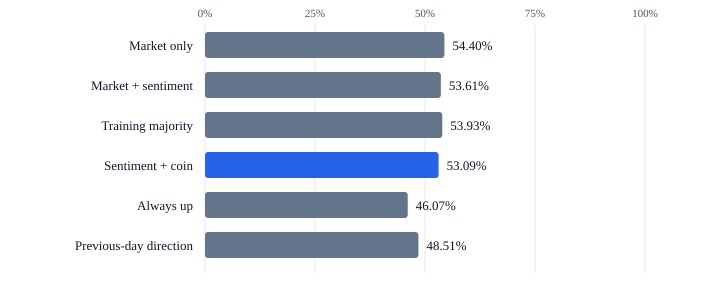

Method,Correct directions,Brier error (lower is better)
Market only,54.40%,0.2477
Market + sentiment,53.61%,0.2486
Training majority,53.93%,0.4607
Sentiment + coin,53.09%,0.2494
Always up,46.07%,0.5393
Previous-day direction,48.51%,0.5149
Coin only,53.93%,0.2485
Training prevalence,53.93%,0.2486


Our model minus,Accuracy difference,Paired 95% interval
Always up,+7.01 pp,"[-1.67, +16.02] pp"
Previous-day direction,+4.58 pp,"[-0.04, +8.69] pp"
Training majority,-0.84 pp,"[-1.83, +0.16] pp"
Market only,-1.32 pp,"[-3.35, +0.80] pp"


Sanity checks: real model 53.09%; permuted-label maximum 54.48%; feature-placebo maximum 54.44%.
The controls refit classifiers; their accuracy need not equal 50% in an imbalanced market.


In [12]:
names = ['Market only', 'Market + sentiment', 'Training majority', 'Sentiment + coin', 'Always up', 'Previous-day direction']
accuracy_chart(report, names)
accuracy_table(report, names + ['Coin only', 'Training prevalence'])
comparisons = []
for name in ['Always up', 'Previous-day direction', 'Training majority', 'Market only']:
    result = report['paired_accuracy_differences'][name]
    low, high = result['interval95']
    comparisons.append({'Our model minus': name, 'Accuracy difference': f"{100 * result['mean']:+.2f} pp",
                        'Paired 95% interval': f'[{100 * low:+.2f}, {100 * high:+.2f}] pp'})
table(pd.DataFrame(comparisons), 'pp = percentage points; these are exploratory intervals')
controls = report['controls']
print(f"Sanity checks: real model {controls['real_accuracy']:.2%}; permuted-label maximum {controls['label_permuted_max']:.2%}; feature-placebo maximum {controls['feature_placebo_max']:.2%}.")
print('The controls refit classifiers; their accuracy need not equal 50% in an imbalanced market.')

### What these results mean
- Up days were less common. The training-majority rule always picked not up and beat the posts-and-coin model.
- Adding posts to the market model increased Brier error by 0.000908 (exploratory 95% interval +0.000238 to +0.001589). The separate paired accuracy intervals above include zero.
- This is a bounded result for **these inputs, models, horizon and dates**—not proof that every kind of financial-text prediction is impossible.

## 11. What should an investor do with this?
| This supports… | This does **not** support… |
|---|---|
| Questioning claims that bullish posts reliably predict tomorrow | Buying, selling, shorting or using leverage from these forecasts |
| Demanding simple baselines, uncertainty and later-date tests | Expecting profits or claiming posts caused a price change |
| Collecting better data and doing a genuinely new future test | Declaring all text-based prediction impossible |

**Limitations:** sparse and selected X coverage; approximate coin tags and keyword labels; shorter histories for later-listed coins; listing/survivorship bias; uncertain pretraining overlap and text-edit history; English text truncated to 128 tokens; repeated exploration of this archive. No fees, slippage, execution or profitability study was performed.

*This project is a prototype and is not financial advice.*

## 12. Protocol tests and reproducibility
The checks cover headline-kind rules, yesterday's matching direction, timestamp handling, price continuity and time splits. A failure stops execution. Full training output is saved in `artifacts/training-log.txt`, rather than filling the notebook with diagnostic JSON.

In [13]:
for filename in ['test_headline_study.py', 'test_expanded_inputs.py']:
    checked = subprocess.run([sys.executable, filename], text=True,
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    if checked.returncode:
        print(checked.stdout)
    checked.check_returncode()
    print('PASS:', filename)
print('Execution environment:', 'Google Colab' if 'google.colab' in sys.modules else 'local Jupyter kernel (not a Colab execution claim)')

PASS: test_headline_study.py


PASS: test_expanded_inputs.py
Execution environment: local Jupyter kernel (not a Colab execution claim)


## Sources, method and credits
- **Posts:** [financial-tweets-crypto](https://huggingface.co/datasets/StephanAkkerman/financial-tweets-crypto), Stephan Akkerman; exact revision and SHA-256 in the [pipeline](https://github.com/adeviwon/hypecheck/blob/e396d50d1ac40eabd648f1cedc4d9316e80e7759/pipeline.py).
- **Sentiment:** [FinTwitBERT-sentiment](https://huggingface.co/StephanAkkerman/FinTwitBERT-sentiment), Stephan Akkerman and Tim Koornstra; frozen, pinned checkpoint. Scores are not human-labelled sentiment truth.
- **Prices:** actual [Binance spot daily OHLCV bars](https://github.com/binance/binance-spot-api-docs/blob/master/rest-api.md#klinecandlestick-data); original provider terms remain separate from our code licence.
- **Exact experiment:** [classifier and evaluation](https://github.com/adeviwon/hypecheck/blob/e396d50d1ac40eabd648f1cedc4d9316e80e7759/headline_study.py), [expanded inputs](https://github.com/adeviwon/hypecheck/blob/e396d50d1ac40eabd648f1cedc4d9316e80e7759/expanded_inputs.py). The setup pins immutable files and verifies their hashes before importing them.
- **Optional independent sentiment recomputation:** rerun `prepare(recompute_sentiment=True)` after setup, then rerun from Section 3. This downloads the frozen encoder; it does not fine-tune it.
- **Tools:** PyTorch, Transformers, scikit-learn, pandas, NumPy, PyArrow, Requests and IPython. Hermes Agent / OpenAI assisted implementation and review; the team must understand and explain the work.
- **Format:** modelled on Veritas AI's ScamCheck sample submission. Finance brief §4.2.4; we adapted the market/source and added time-aware baselines, uncertainty, controls, text-kind tests and replay.